# EDA (Exploratory Data Analysis)
Analizar y entender a fondo el dataset 

## Se cargan las librerías necesarias


In [22]:
import pandas as pd #carga de datos
import numpy  as np #analisis de datos
import matplotlib.pyplot as plt #Gráficas
import seaborn as sns #parte estética de las gráficas

## Carga del archivo
Usando pandas se carga el archivo csv donde están los datos y guardarlo en la variable de data frame (df) y mostramos los primeros datos

In [23]:
df = pd.read_csv('../data/raw/bank-full.csv', sep=';') #carga de datos desde un archivo CSV
df.head() #muestra las primeras filas del DataFrame

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [24]:
print(df.info()) #muestra información sobre el DataFrame, incluyendo el número de filas y columnas, los tipos de datos y la cantidad de valores nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
None


## Limpieza y calidad de los datos
Podemos observar que no hay valores nulos, pero se necesita quitar si hay filas duplicadas.

También se revisa las columnas que sean de tipo objeto (category o string), cuenta cuántos son " unknown " e indica el porcentaje en relacion con el total de registros

Finalmente, se transforman los datos de salida (y) de categorias entre si y no, en valores binarios (1 o 0)


In [ ]:
# 1. Nulos explícitos y duplicados
print("Valores nulos por columna:\n", df.isna().sum())
print("Filas duplicadas:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("\n")

# 2. Revisar 'unknown' en variables categóricas
cat_cols = df.select_dtypes(include="object").columns.tolist()
for col in cat_cols:
  unk_count = (df[col] == "unknown").sum()
  if unk_count > 0:
    print(f"{col}: {unk_count} 'unknown' ({unk_count/len(df)*100:.2f}%)")

# 3. Variable objetivo binaria, convierte 'yes' a 1 y 'no' a 0
df["y"] = df["y"].map({"yes": 1, "no": 0})

Valores nulos por columna:
 age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Filas duplicadas: 0


job: 288 'unknown' (0.64%)
education: 1857 'unknown' (4.11%)
contact: 13020 'unknown' (28.80%)
poutcome: 36959 'unknown' (81.75%)


In [26]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0


## Análisis univariado

### Desbalance de la variable objetivo o de salida (y)
Nos sirve para ver que porcentaje de todos los datos tienen salida Si (1) y No (0), para observar que tan desvalanceado es el conjunto de datos

y
0    88.30152
1    11.69848
Name: proportion, dtype: float64


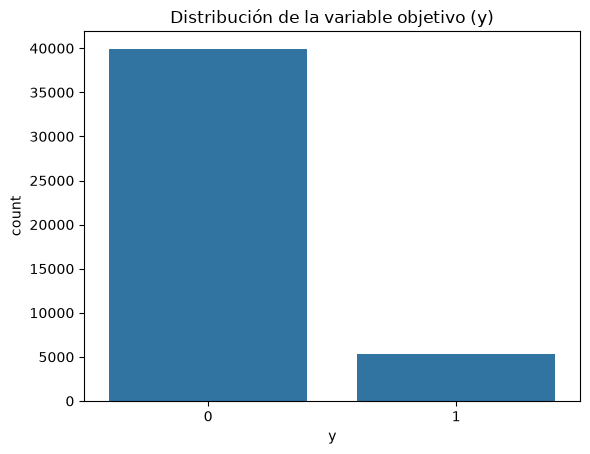

In [27]:
# Desbalance de clases en la variable objetivo
print(df["y"].value_counts(normalize=True) * 100)
sns.countplot(x="y", data=df)
plt.title("Distribución de la variable objetivo (y)")
plt.show()

### Variables numéricas
Nos permite observar de forma gráfica las variables numéricas, a traves de un histograma la distribucion, si tiene uno o varios picos. 

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


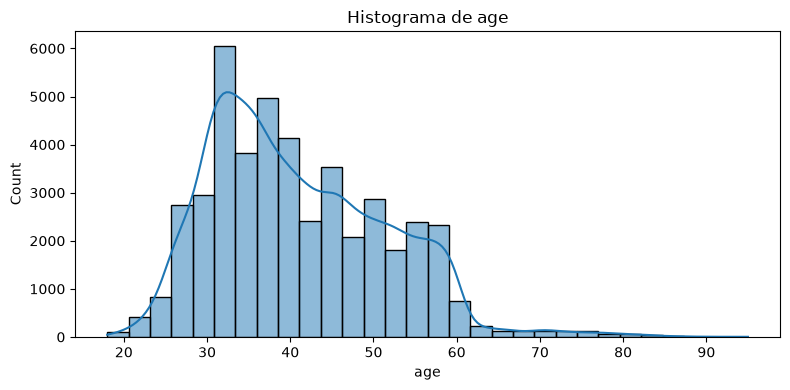

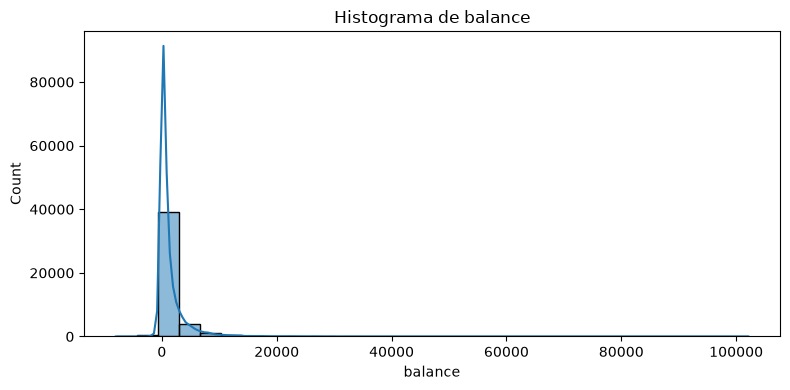

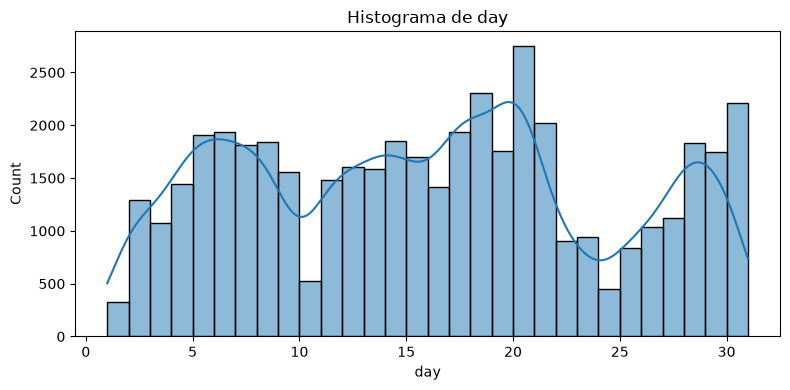

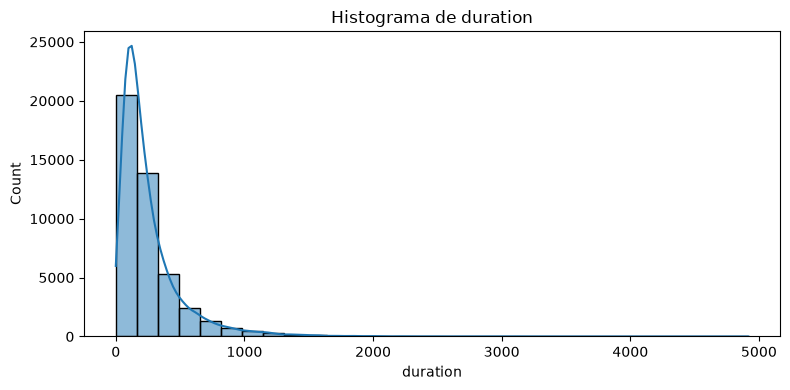

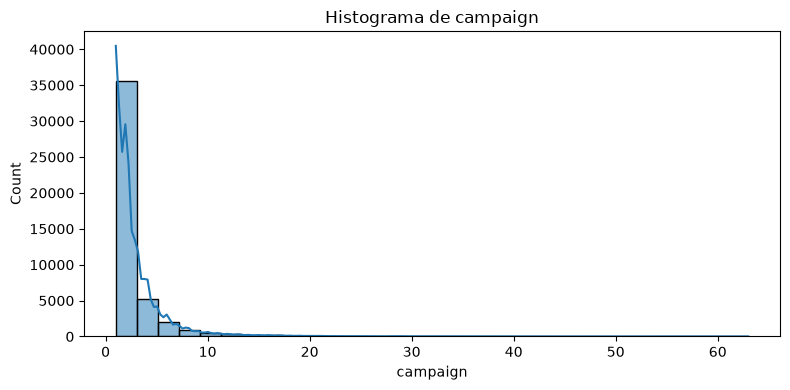

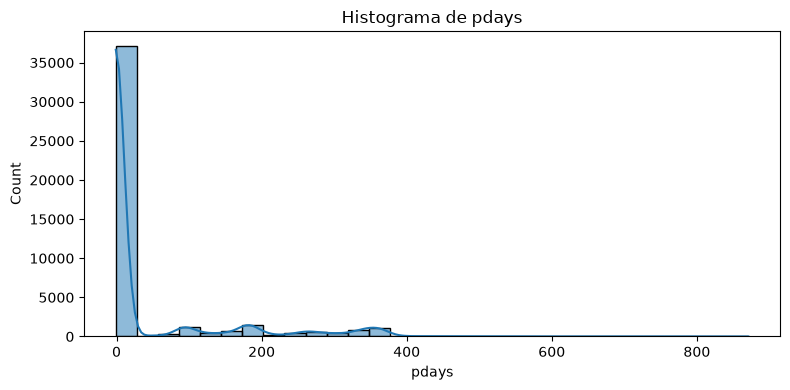

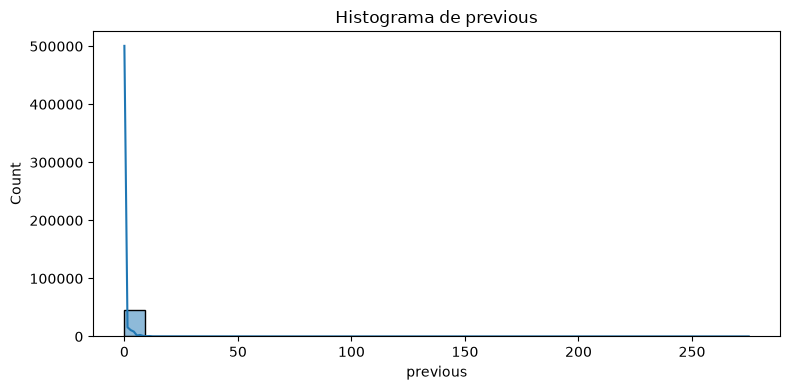

In [32]:
# Variables numéricas
num_cols = df.select_dtypes(include=[np.number]).drop(columns=["y"]).columns
display(df[num_cols].describe().T)

for col in num_cols:
  fig, axes = plt.subplots(1, 1, figsize=(8, 4))
  sns.histplot(df[col], kde=True, bins=30, ax=axes)
  axes.set_title(f"Histograma de {col}")
  plt.tight_layout()
  plt.show()

### Variables categóricas


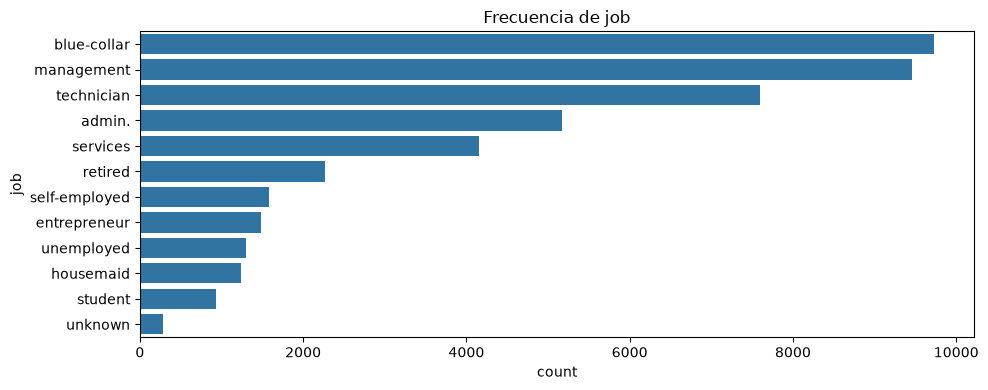

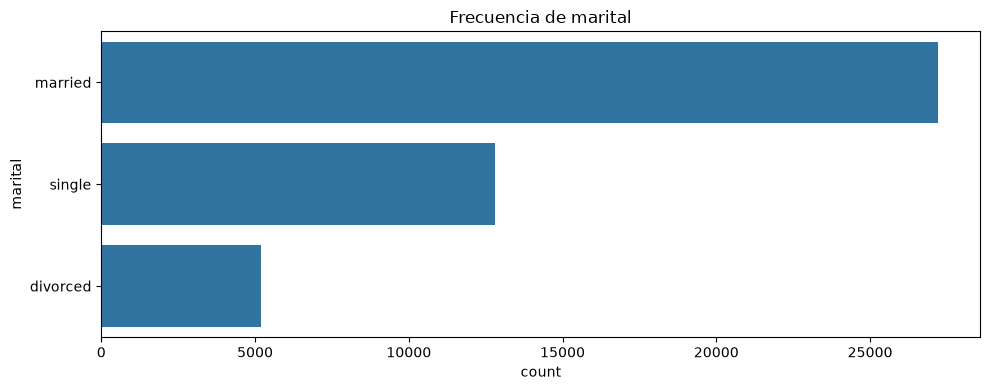

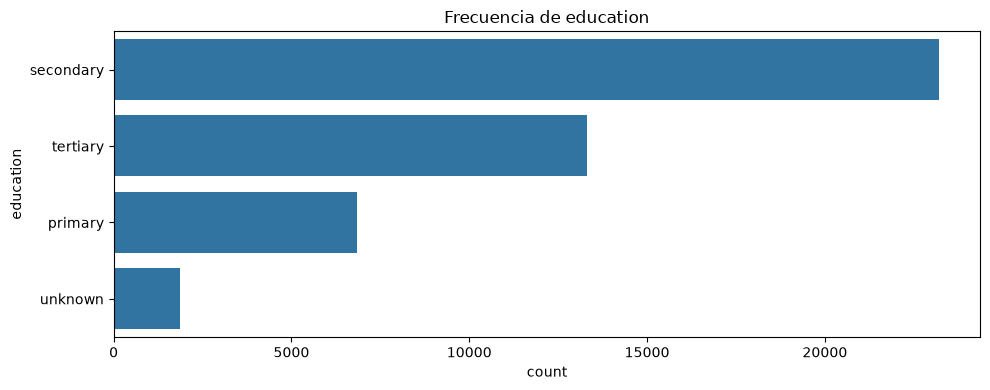

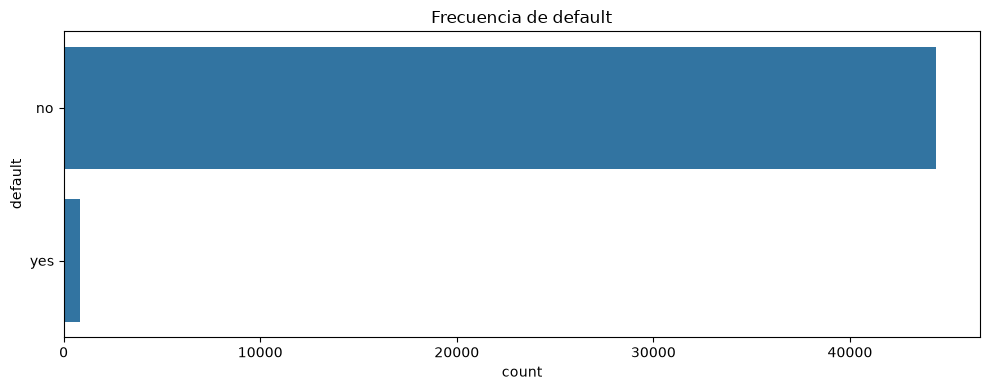

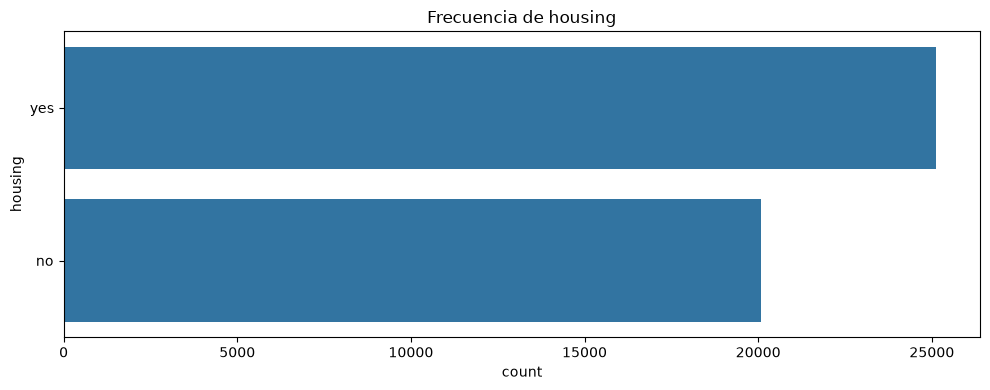

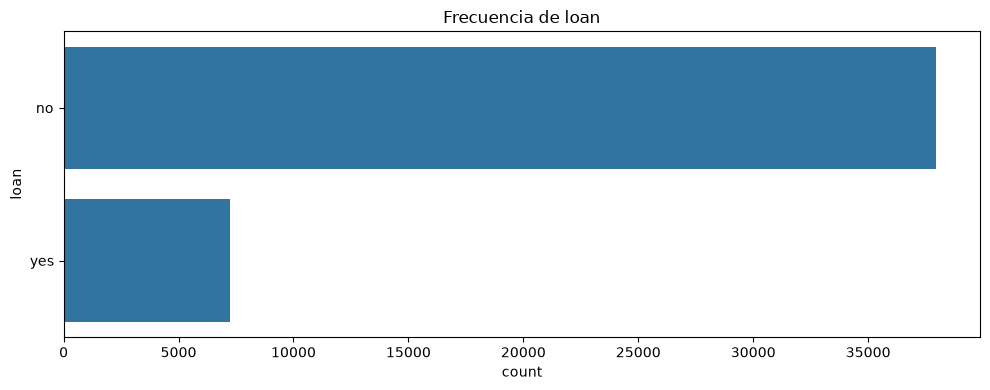

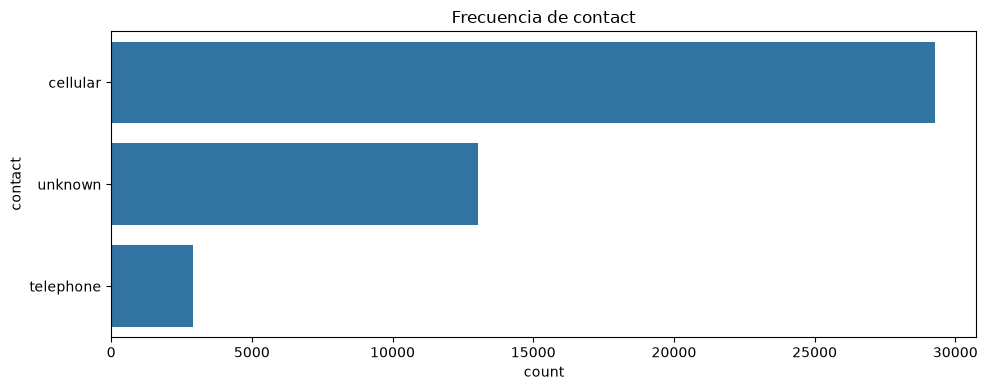

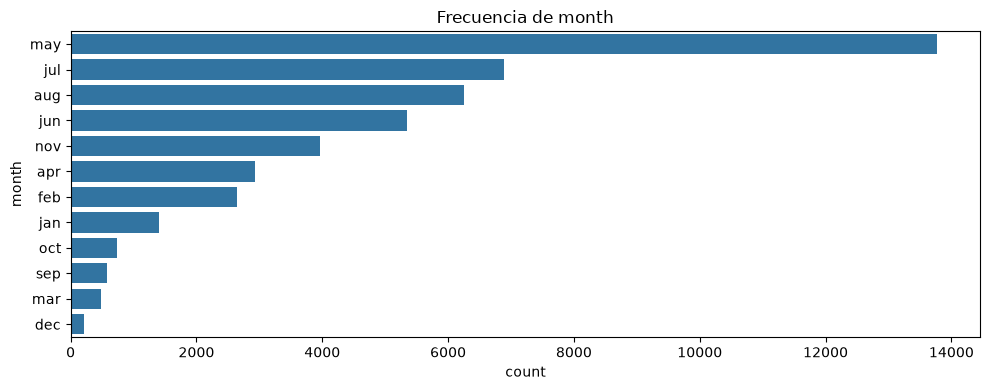

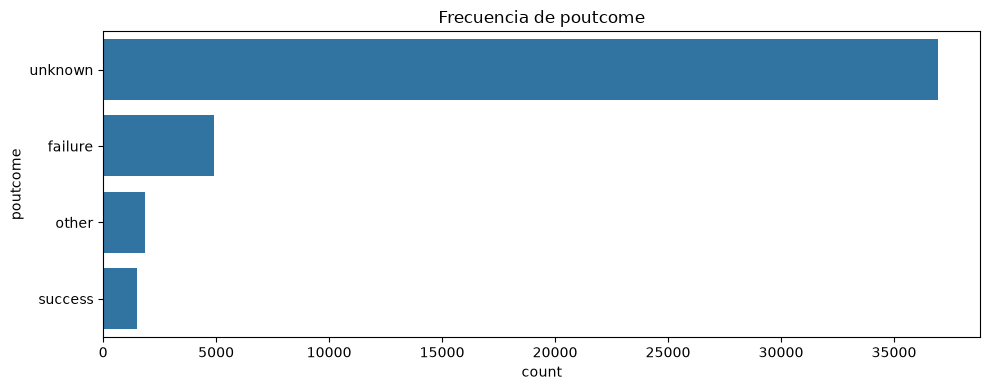

In [33]:
# Variables categóricas principales
for col in [c for c in cat_cols if c != "y"]:
  plt.figure(figsize=(10, 4))
  order = df[col].value_counts().index
  sns.countplot(y=col, data=df, order=order)
  plt.title(f"Frecuencia de {col}")
  plt.tight_layout()
  plt.show()